In [ ]:

import pandas as pd

# Create a sample cybersecurity dataset
data = {
    "timestamp": [
        "2026-10-13 09:00", "2026-10-13 09:01",
        "2026-10-13 09:02", "2026-10-13 09:03",
        "2026-10-13 09:04", "2026-10-13 09:05",
        "2026-10-13 09:06", "2026-10-13 09:07",
        "2026-10-13 09:08", "2026-10-13 09:09",
        "2026-10-13 09:10", "2026-10-13 09:11",
        "2026-10-13 09:12", "2026-10-13 09:13",
        "2026-10-13 09:14", "2026-10-13 09:15",
        "2026-10-13 09:16", "2026-10-13 09:17",
        "2026-10-13 09:18", "2026-10-13 09:19"
    ],
    "user_id": [
        "U001", "U002", "U002", "U002", "U002",
        "U003", "U001", "U004", "U004", "U002",
        "U005", "U003", "U002", "U001", "U004",
        "U006", "U002", "U003", "U005", "U001"
    ],
    "source_ip": [
        "192.0.2.10", "192.0.2.20", "192.0.2.20",
        "192.0.2.20", "192.0.2.20", "192.0.2.30",
        "192.0.2.10", "192.0.2.40", "192.0.2.40",
        "192.0.2.20", "192.0.2.50", "192.0.2.30",
        "192.0.2.20", "192.0.2.10", "192.0.2.40",
        "192.0.2.60", "192.0.2.20", "192.0.2.30",
        "192.0.2.50", "192.0.2.10"
    ],
    "status": [
        "Success", "Failed", "Failed", "Failed", "Failed",
        "Success", "Success", "Failed", "Success", "Failed",
        "Success", "Failed", "Failed", "Success", "Success",
        "Failed", "Failed", "Success", "Success", "Success"
    ]
}

df = pd.DataFrame(data)

print("CyberShield Analytics")
print("Dataset loaded successfully!")
print("Number of records:", len(df))

df.head(10)

CyberShield Analytics
Dataset loaded successfully!
Number of records: 20


,timestamp,user_id,source_ip,status
0,2026-10-13 09:00,U001,192.0.2.10,Success
1,2026-10-13 09:01,U002,192.0.2.20,Failed
2,2026-10-13 09:02,U002,192.0.2.20,Failed
3,2026-10-13 09:03,U002,192.0.2.20,Failed
4,2026-10-13 09:04,U002,192.0.2.20,Failed
5,2026-10-13 09:05,U003,192.0.2.30,Success
6,2026-10-13 09:06,U001,192.0.2.10,Success
7,2026-10-13 09:07,U004,192.0.2.40,Failed
8,2026-10-13 09:08,U004,192.0.2.40,Success
9,2026-10-13 09:09,U002,192.0.2.20,Failed


In [ ]:

# Count successful and failed login attempts
login_counts = df["status"].value_counts()

print("Login Outcome Analysis")
print("----------------------")
print("Successful logins:", login_counts.get("Success", 0))
print("Failed logins:", login_counts.get("Failed", 0))

# Calculate the failure percentage
total_attempts = len(df)
failed_attempts = (df["status"] == "Failed").sum()

failure_percentage = (failed_attempts / total_attempts) * 100

print("Total login attempts:", total_attempts)
print("Failure percentage:", round(failure_percentage, 2), "%")

Login Outcome Analysis
----------------------
Successful logins: 10
Failed logins: 10
Total login attempts: 20
Failure percentage: 50.0 %


In [ ]:

# Select only failed login attempts
failed_logins = df[df["status"] == "Failed"]

# Count failed attempts for each user
failures_by_user = (
    failed_logins["user_id"]
    .value_counts()
)

print("Failed Login Attempts by User")
print("------------------------------")
print(failures_by_user)

Failed Login Attempts by User
------------------------------
user_id
U002    7
U004    1
U003    1
U006    1
Name: count, dtype: int64


In [ ]:

# Get the number of failed attempts for U002
u002_failures = failures_by_user.get("U002", 0)

print("User ID: U002")
print("Failed login attempts:", u002_failures)

if u002_failures >= 5:
    print("Alert: Repeated failed logins detected.")
else:
    print("Continue monitoring login activity.")

User ID: U002
Failed login attempts: 7
Alert: Repeated failed logins detected.


In [ ]:

# Set our alert threshold
threshold = 5

# Identify accounts that meet or exceed the threshold
security_alerts = failures_by_user[failures_by_user >= threshold]

print("CYBERSHIELD ANALYTICS")
print("=====================")
print("Security Alert Report")

if len(security_alerts) > 0:
    for user, count in security_alerts.items():
        print(
            f"ALERT: {user} recorded {count} "
            "failed login attempts."
        )
        print("Action: Investigate the activity.")
else:
    print("No accounts met the alert threshold.")

CYBERSHIELD ANALYTICS
Security Alert Report
ALERT: U002 recorded 7 failed login attempts.
Action: Investigate the activity.


In [ ]:

# Count failed login attempts by source IP
failures_by_ip = (
    failed_logins["source_ip"]
    .value_counts()
)

print("Failed Login Attempts by Source IP")
print("----------------------------------")
print(failures_by_ip)

Failed Login Attempts by Source IP
----------------------------------
source_ip
192.0.2.20    7
192.0.2.40    1
192.0.2.30    1
192.0.2.60    1
Name: count, dtype: int64


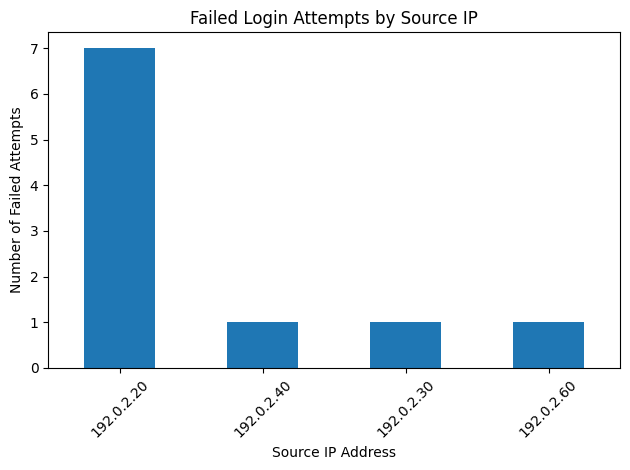

In [ ]:

import matplotlib.pyplot as plt

# Plot failed login attempts by source IP
failures_by_ip.plot(kind="bar")

plt.title("Failed Login Attempts by Source IP")
plt.xlabel("Source IP Address")
plt.ylabel("Number of Failed Attempts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Failed Login Attempts Over Time
timestamp
2026-10-13 09:01:00    1
2026-10-13 09:02:00    1
2026-10-13 09:03:00    1
2026-10-13 09:04:00    1
2026-10-13 09:05:00    0
2026-10-13 09:06:00    0
2026-10-13 09:07:00    1
2026-10-13 09:08:00    0
2026-10-13 09:09:00    1
2026-10-13 09:10:00    0
2026-10-13 09:11:00    1
2026-10-13 09:12:00    1
2026-10-13 09:13:00    0
2026-10-13 09:14:00    0
2026-10-13 09:15:00    1
2026-10-13 09:16:00    1
Freq: min, dtype: int64


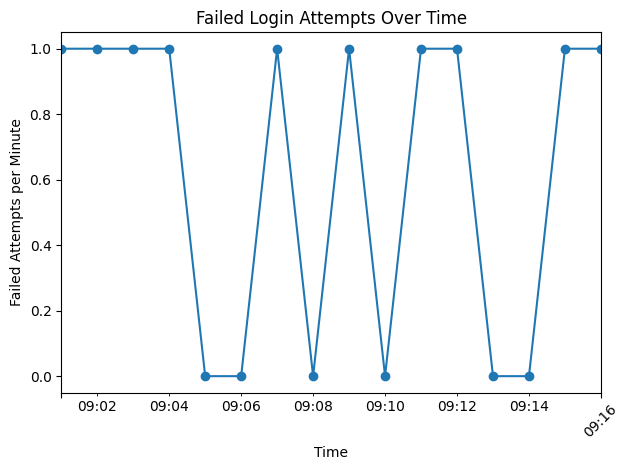

In [ ]:

# Convert timestamps into Python datetime values
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Keep only failed login attempts
failed_logins = df[df["status"] == "Failed"].copy()

# Count failed attempts per minute
failures_by_minute = (
    failed_logins
    .set_index("timestamp")
    .resample("1min")
    .size()
)

print("Failed Login Attempts Over Time")
print(failures_by_minute)

# Visualize the pattern
failures_by_minute.plot(kind="line", marker="o")

plt.title("Failed Login Attempts Over Time")
plt.xlabel("Time")
plt.ylabel("Failed Attempts per Minute")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# Generate a CyberShield Analytics report

total = len(df)
successful = (df["status"] == "Success").sum()
failed = (df["status"] == "Failed").sum()

top_user = failures_by_user.idxmax()
top_user_count = failures_by_user.max()

top_ip = failures_by_ip.idxmax()
top_ip_count = failures_by_ip.max()

print("CYBERSHIELD ANALYTICS")
print("SECURITY ANALYSIS REPORT")
print("=" * 35)

print(f"Total login attempts: {total}")
print(f"Successful logins: {successful}")
print(f"Failed logins: {failed}")
print(f"Failure rate: {failed / total * 100:.1f}%")

print("\nKEY FINDINGS")
print(
    f"Account with most failures: "
    f"{top_user} ({top_user_count})"
)
print(
    f"Source IP with most failures: "
    f"{top_ip} ({top_ip_count})"
)

print("\nRECOMMENDATIONS")
print("1. Investigate repeated failed login attempts.")
print("2. Review authentication and access controls.")
print("3. Consider multifactor authentication.")
print("4. Continue monitoring for unusual activity.")

print("\nLIMITATIONS")
print("This report uses synthetic training data.")
print("The findings do not prove an actual cyberattack.")

CYBERSHIELD ANALYTICS
SECURITY ANALYSIS REPORT
Total login attempts: 20
Successful logins: 10
Failed logins: 10
Failure rate: 50.0%

KEY FINDINGS
Account with most failures: U002 (7)
Source IP with most failures: 192.0.2.20 (7)

RECOMMENDATIONS
1. Investigate repeated failed login attempts.
2. Review authentication and access controls.
3. Consider multifactor authentication.
4. Continue monitoring for unusual activity.

LIMITATIONS
This report uses synthetic training data.
The findings do not prove an actual cyberattack.


In [10]:

# CyberShield Analytics: IP Security Summary

ip_security_summary = failures_by_ip.reset_index()
ip_security_summary.columns = ["Source IP", "Failed Attempts"]

ip_security_summary["Alert"] = ip_security_summary[
    "Failed Attempts"
].apply(
    lambda count: "Review Required" if count >= 5 else "Normal"
)

ip_security_summary = ip_security_summary.sort_values(
    by="Failed Attempts",
    ascending=False
)

print("FAILED LOGIN SUMMARY BY IP ADDRESS")
display(ip_security_summary)

FAILED LOGIN SUMMARY BY IP ADDRESS


,Source IP,Failed Attempts,Alert
0,192.0.2.20,7,Review Required
1,192.0.2.40,1,Normal
2,192.0.2.30,1,Normal
3,192.0.2.60,1,Normal


In [11]:

# CyberShield Analytics: Security Dashboard Metrics

total_attempts = len(df)
successful_attempts = (df["status"] == "Success").sum()
failed_attempts = (df["status"] == "Failed").sum()

failure_rate = (failed_attempts / total_attempts) * 100

users_flagged = (failures_by_user >= threshold).sum()
ips_flagged = (failures_by_ip >= threshold).sum()

print("===== CYBERSHIELD SECURITY SUMMARY =====")
print(f"Total Login Attempts: {total_attempts}")
print(f"Successful Logins: {successful_attempts}")
print(f"Failed Logins: {failed_attempts}")
print(f"Login Failure Rate: {failure_rate:.1f}%")
print(f"Users Requiring Review: {users_flagged}")
print(f"IP Addresses Requiring Review: {ips_flagged}")
print("========================================")

===== CYBERSHIELD SECURITY SUMMARY =====
Total Login Attempts: 20
Successful Logins: 10
Failed Logins: 10
Login Failure Rate: 50.0%
Users Requiring Review: 1
IP Addresses Requiring Review: 1


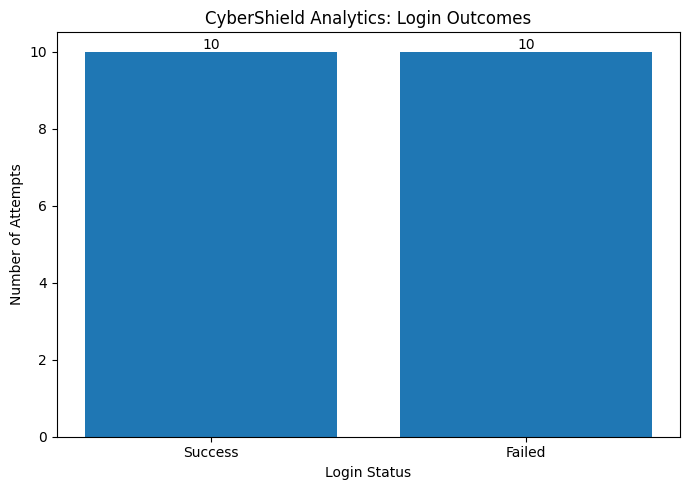

In [12]:

# CyberShield Analytics: Login Outcome Dashboard

import matplotlib.pyplot as plt

login_outcomes = df["status"].value_counts().reindex(
    ["Success", "Failed"], fill_value=0
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    login_outcomes.index,
    login_outcomes.values
)

plt.title("CyberShield Analytics: Login Outcomes")
plt.xlabel("Login Status")
plt.ylabel("Number of Attempts")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [13]:

# CyberShield Analytics: Analyst Interpretation

print("===== SECURITY ANALYST INTERPRETATION =====")

print(
    f"Out of {total_attempts} login attempts, "
    f"{failed_attempts} failed."
)

print(f"The login failure rate is {failure_rate:.1f}%.")

if users_flagged > 0:
    print(
        f"REVIEW: {users_flagged} user account(s) "
        f"met the failed-login threshold of {threshold}."
    )
else:
    print("No user accounts met the review threshold.")

if ips_flagged > 0:
    print(
        f"REVIEW: {ips_flagged} source IP address(es) "
        f"met the failed-login threshold of {threshold}."
    )
else:
    print("No source IP addresses met the review threshold.")

print(
    "RECOMMENDATION: Review authentication logs, "
    "check for legitimate user errors, and investigate "
    "repeated failures before drawing conclusions."
)

print(
    "LIMITATION: This is simulated training data. "
    "The alerts do not prove malicious activity."
)

print("===========================================")

===== SECURITY ANALYST INTERPRETATION =====
Out of 20 login attempts, 10 failed.
The login failure rate is 50.0%.
REVIEW: 1 user account(s) met the failed-login threshold of 5.
REVIEW: 1 source IP address(es) met the failed-login threshold of 5.
RECOMMENDATION: Review authentication logs, check for legitimate user errors, and investigate repeated failures before drawing conclusions.
LIMITATION: This is simulated training data. The alerts do not prove malicious activity.


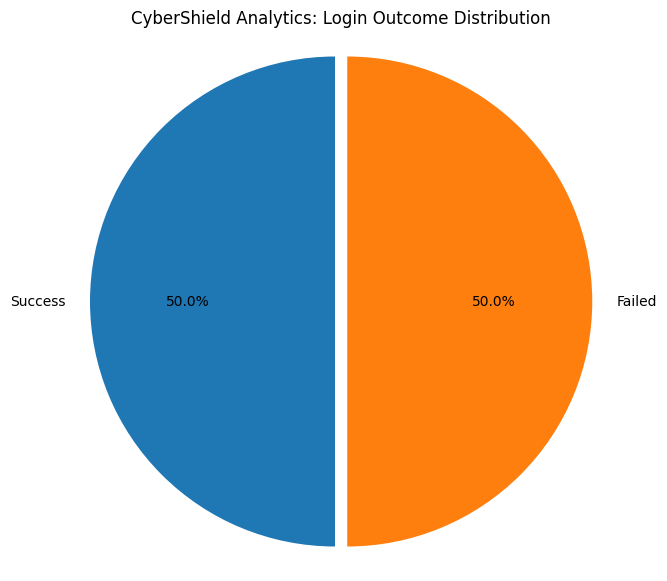

In [14]:

# CyberShield Analytics: Login Outcome Pie Chart

import matplotlib.pyplot as plt

login_outcomes = df["status"].value_counts().reindex(
    ["Success", "Failed"], fill_value=0
)

plt.figure(figsize=(7, 7))

plt.pie(
    login_outcomes.values,
    labels=login_outcomes.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.05)
)

plt.title("CyberShield Analytics: Login Outcome Distribution")
plt.axis("equal")
plt.show()

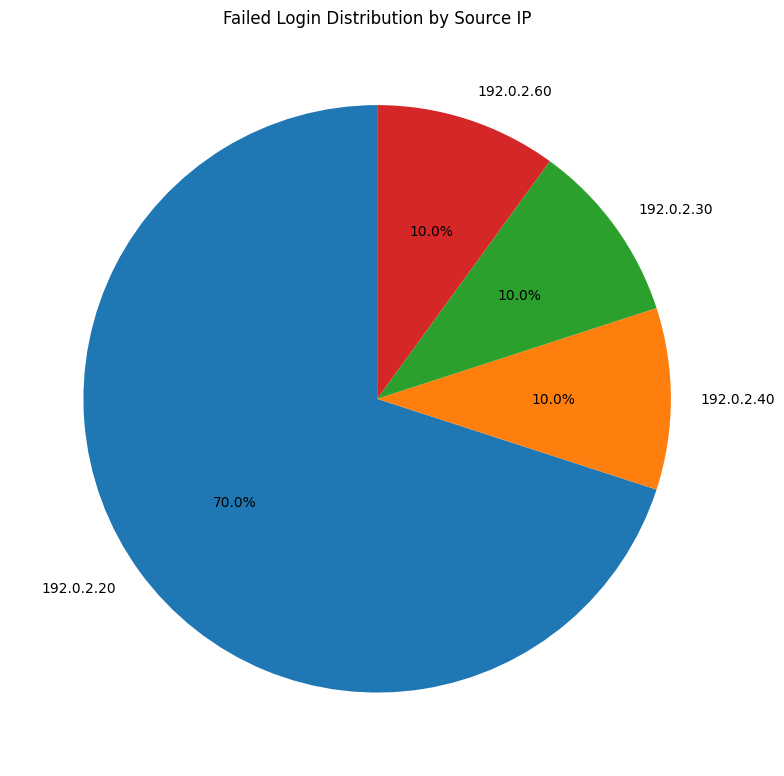

In [15]:

# CyberShield Analytics: Failed Logins by Source IP

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

failures_by_ip.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Failed Login Distribution by Source IP")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [16]:

# CyberShield Analytics: Project Report

print("=" * 55)
print("          CYBERSHIELD ANALYTICS REPORT")
print("=" * 55)

print("\n1. PROJECT OBJECTIVE")
print(
    "Analyze authentication logs to identify repeated "
    "failed login attempts and patterns requiring review."
)

print("\n2. DATASET OVERVIEW")
print(f"Total login events: {total_attempts}")
print(f"Successful logins: {successful_attempts}")
print(f"Failed logins: {failed_attempts}")
print(f"Failure rate: {failure_rate:.1f}%")

print("\n3. KEY FINDINGS")
print(
    f"User with the most failed attempts: "
    f"{top_user} ({top_user_count} attempts)"
)
print(
    f"IP with the most failed attempts: "
    f"{top_ip} ({top_ip_count} attempts)"
)
print(f"Review threshold: {threshold} failed attempts")

print("\n4. METHODS USED")
print(
    "Python, Pandas, data filtering, aggregation, "
    "rule-based alerting, Matplotlib visualizations."
)

print("\n5. RECOMMENDATIONS")
print(
    "Review repeated login failures, verify legitimate "
    "user activity, and investigate relevant logs."
)

print("\n6. LIMITATIONS")
print(
    "The dataset is simulated and contains only 20 events. "
    "The findings do not establish that an attack occurred."
)

print("\n7. FUTURE IMPROVEMENTS")
print(
    "Analyze larger datasets, add time-window detection, "
    "and build an interactive security dashboard."
)

print("\n" + "=" * 55)
print("                 END OF REPORT")
print("=" * 55)

          CYBERSHIELD ANALYTICS REPORT

1. PROJECT OBJECTIVE
Analyze authentication logs to identify repeated failed login attempts and patterns requiring review.

2. DATASET OVERVIEW
Total login events: 20
Successful logins: 10
Failed logins: 10
Failure rate: 50.0%

3. KEY FINDINGS
User with the most failed attempts: U002 (7 attempts)
IP with the most failed attempts: 192.0.2.20 (7 attempts)
Review threshold: 5 failed attempts

4. METHODS USED
Python, Pandas, data filtering, aggregation, rule-based alerting, Matplotlib visualizations.

5. RECOMMENDATIONS
Review repeated login failures, verify legitimate user activity, and investigate relevant logs.

6. LIMITATIONS
The dataset is simulated and contains only 20 events. The findings do not establish that an attack occurred.

7. FUTURE IMPROVEMENTS
Analyze larger datasets, add time-window detection, and build an interactive security dashboard.

                 END OF REPORT
